## data ingestaion

In [97]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mehmetsabrikunt/internet-service-churn")

print("Path to dataset files:", path)

Path to dataset files: /Users/mohaiminulislam/.cache/kagglehub/datasets/mehmetsabrikunt/internet-service-churn/versions/5


In [98]:
from pathlib import Path
data_path= Path(path)
for file in data_path.iterdir():
    print(file.name)

internet_service_churn.csv


In [99]:
data_path


PosixPath('/Users/mohaiminulislam/.cache/kagglehub/datasets/mehmetsabrikunt/internet-service-churn/versions/5')

In [100]:
import pandas as pd 
data= pd.read_csv(data_path/'internet_service_churn.csv')
data.head()

,id,is_tv_subscriber,is_movie_package_subscriber,subscription_age,bill_avg,reamining_contract,service_failure_count,download_avg,upload_avg,download_over_limit,churn
0,15,1,0,11.95,25,0.14,0,8.4,2.3,0,0
1,18,0,0,8.22,0,NaN,0,0.0,0.0,0,1
2,23,1,0,8.91,16,0.00,0,13.7,0.9,0,1
3,27,0,0,6.87,21,NaN,1,0.0,0.0,0,1
4,34,0,0,6.39,0,NaN,0,0.0,0.0,0,1


In [101]:
output_path= Path("../data/raw")/"internet_service_churn.csv"

data.to_csv(output_path, index=False)

In [102]:
print(data_path)

/Users/mohaiminulislam/.cache/kagglehub/datasets/mehmetsabrikunt/internet-service-churn/versions/5


## data investigation


In [103]:
for col in data.columns:
    print(f"{col}: unique_value={data[col].nunique()}, null_values={data[col].isnull().sum()}, dtype={data[col].dtype}")

id: unique_value=72274, null_values=0, dtype=int64
is_tv_subscriber: unique_value=2, null_values=0, dtype=int64
is_movie_package_subscriber: unique_value=2, null_values=0, dtype=int64
subscription_age: unique_value=1110, null_values=0, dtype=float64
bill_avg: unique_value=179, null_values=0, dtype=int64
reamining_contract: unique_value=247, null_values=21572, dtype=float64
service_failure_count: unique_value=19, null_values=0, dtype=int64
download_avg: unique_value=2856, null_values=381, dtype=float64
upload_avg: unique_value=802, null_values=381, dtype=float64
download_over_limit: unique_value=8, null_values=0, dtype=int64
churn: unique_value=2, null_values=0, dtype=int64


In [104]:
data.isnull().sum()

id                                 0
is_tv_subscriber                   0
is_movie_package_subscriber        0
subscription_age                   0
bill_avg                           0
reamining_contract             21572
service_failure_count              0
download_avg                     381
upload_avg                       381
download_over_limit                0
churn                              0
dtype: int64

In [105]:
for i , n in enumerate(data.isnull().sum()):
    if n!=0:
    
        print(f"{data.columns[i]}= {round(n/len(data),3)*100}%")

reamining_contract= 29.799999999999997%
download_avg= 0.5%
upload_avg= 0.5%


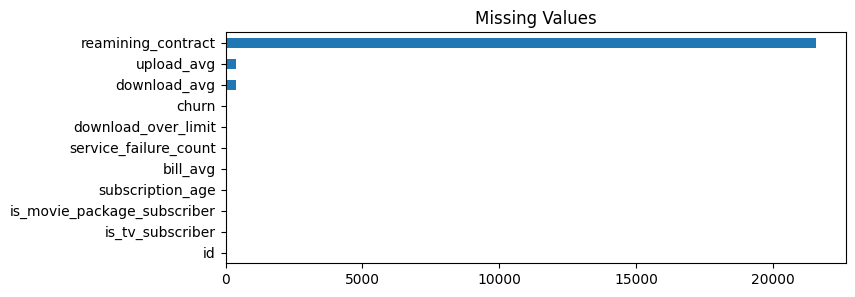

In [106]:
import matplotlib.pyplot as plt
from scipy import stats# Plot
plt.figure(figsize=(8,3))
data.isnull().sum().sort_values(ascending=True).plot(kind='barh')
plt.title("Missing Values")
plt.show()

In [107]:
data.groupby(data["reamining_contract"].isna())["churn"].agg(["count", "mean"])
    

,count,mean
reamining_contract,,
False,50702,0.400990
True,21572,0.914102


In [108]:
for col in data.columns:
    if (data[col]< 0).any():
        print(f"{col}: {[data.loc[data[col] < 0,col]]}")

subscription_age: [69320   -0.02
Name: subscription_age, dtype: float64]


In [109]:
data.loc[69320]

id                             1621523.00
is_tv_subscriber                     0.00
is_movie_package_subscriber          0.00
subscription_age                    -0.02
bill_avg                             0.00
reamining_contract                   0.08
service_failure_count                0.00
download_avg                        32.60
upload_avg                           1.30
download_over_limit                  0.00
churn                                1.00
Name: 69320, dtype: float64

In [110]:
duplicates = data[data.duplicated()]

print(duplicates)

Empty DataFrame
Columns: [id, is_tv_subscriber, is_movie_package_subscriber, subscription_age, bill_avg, reamining_contract, service_failure_count, download_avg, upload_avg, download_over_limit, churn]
Index: []


In [111]:
print(f"number of duplicate values: {data.duplicated().sum()/len(data)*100:.2f}%")

number of duplicate values: 0.00%


## data_transformation


In [112]:
data= data.drop(["id"], axis=1)

In [113]:
data= data.drop(index=69320)

In [114]:
data.drop_duplicates(keep='first', inplace=True)

In [115]:
data["reamining_contract"].values

array([0.14,  nan, 0.  , ..., 2.19, 0.72, 0.82], shape=(70124,))

In [116]:
data=data.rename(columns={"reamining_contract": "remaining_contract"})

In [117]:
median_contract = data["remaining_contract"].median()

data["missing_remaining_contract"] = data["remaining_contract"].isna().astype(int)
data["remaining_contract"] = data["remaining_contract"].fillna(median_contract)


In [118]:
data["download_avg"]= data["download_avg"].fillna(data["download_avg"].median())
data["upload_avg"]= data["upload_avg"].fillna(data["upload_avg"].median())

In [119]:
data.dtypes

is_tv_subscriber                 int64
is_movie_package_subscriber      int64
subscription_age               float64
bill_avg                         int64
remaining_contract             float64
service_failure_count            int64
download_avg                   float64
upload_avg                     float64
download_over_limit              int64
churn                            int64
missing_remaining_contract       int64
dtype: object

In [ ]:
positive_continuous_cols= [,
       'subscription_age', 'bill_avg', 'remaining_contract',
       'service_failure_count', 'download_avg', 'upload_avg',
       'download_over_limit']



SyntaxError: invalid syntax (497415478.py, line 1)

## correlation

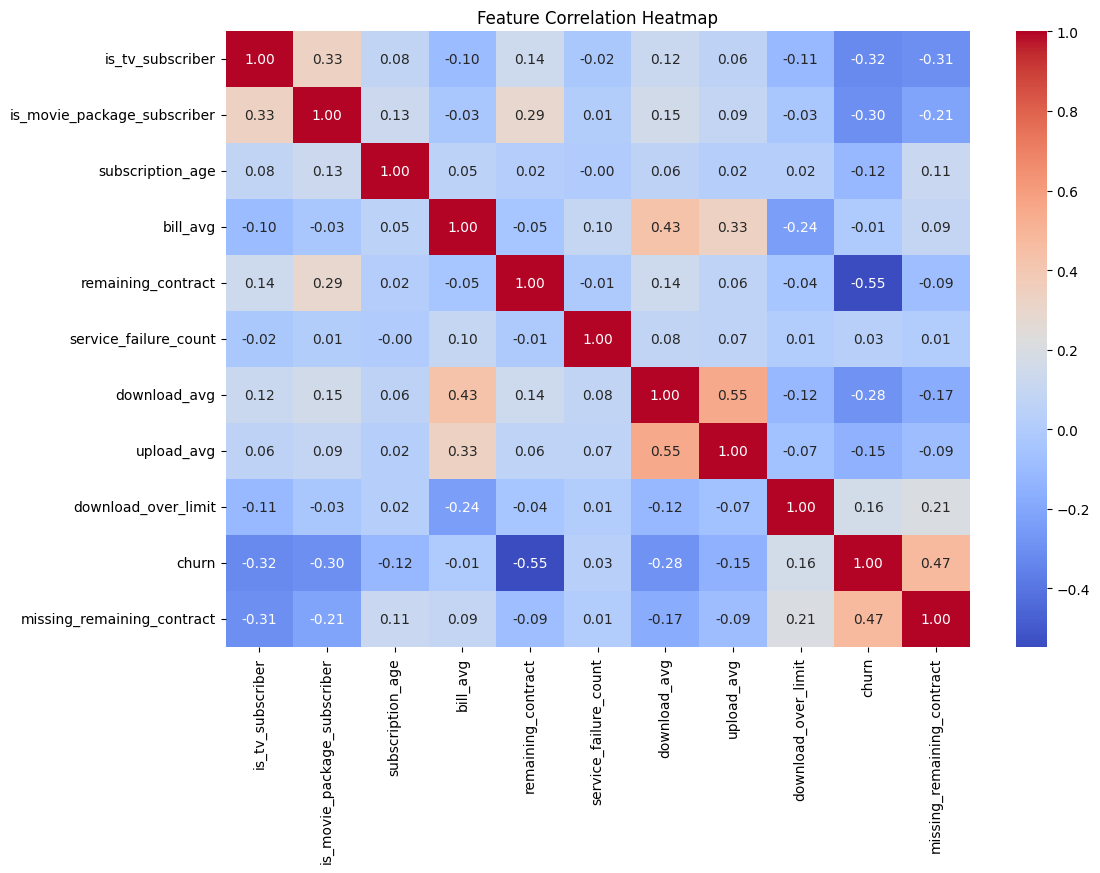

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

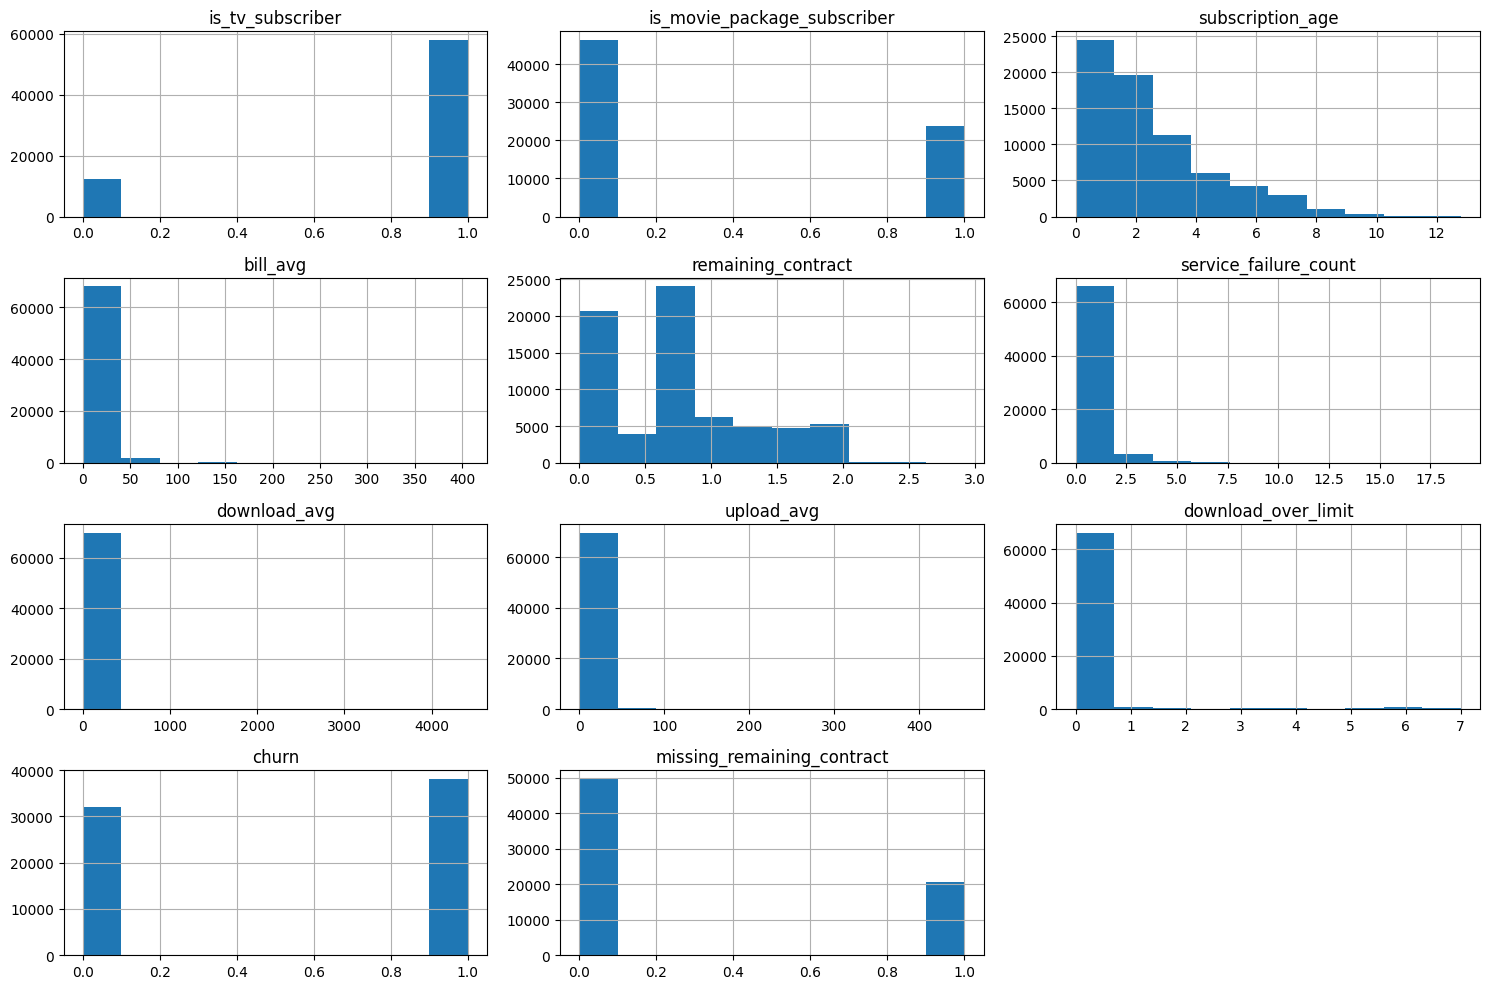

In [ ]:
data.hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

## feature Engeneering


In [ ]:
data["num_services_subscribed"]= data[["is_tv_subscriber", "is_movie_package_subscriber"]].sum(axis=1)



In [ ]:

total_usage= data[["download_avg", "upload_avg"]].sum(axis=1)
data["cost_per_usage"]= np.where(
    total_usage>0,
    data["bill_avg"]/total_usage,
    0
    )

## BOXPLOT

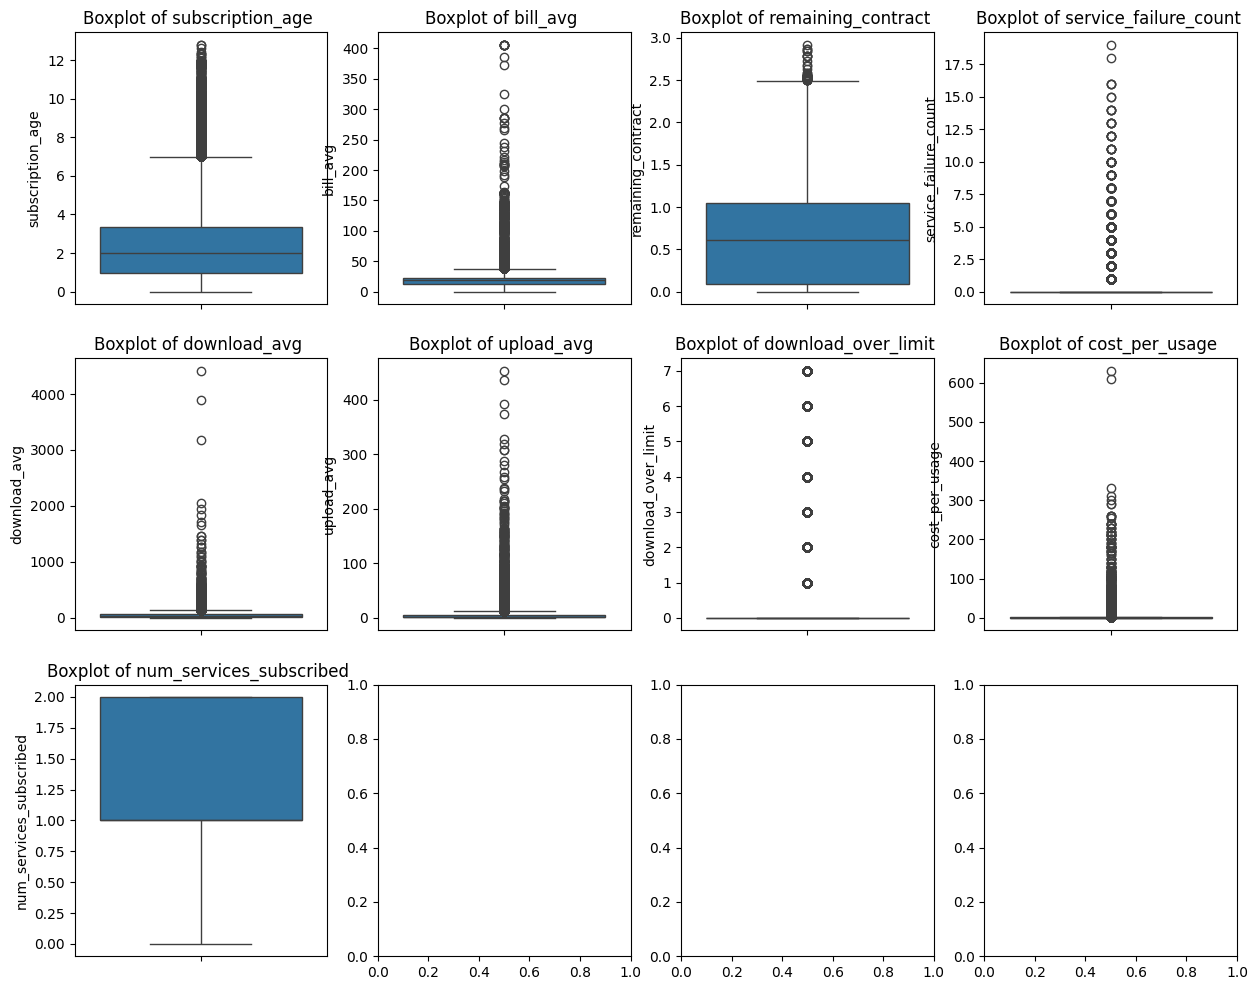

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(15, 12))

axes = axes.flatten()
Numeric_cols= ['subscription_age','bill_avg', 'remaining_contract','service_failure_count','download_avg', 'upload_avg', 'download_over_limit','cost_per_usage','num_services_subscribed']

for i, col in enumerate(Numeric_cols):
    sns.boxplot(y=data[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col} ")
    
plt.show()

## train test split and scaling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression



scaler= StandardScaler()
Numeric_cols= ['subscription_age','bill_avg', 'remaining_contract','service_failure_count','download_avg', 'upload_avg', 'download_over_limit','cost_per_usage','num_services_subscribed']
Binary_cols= ['is_tv_subscriber', 'is_movie_package_subscriber']
Target_col="churn"
X= data[Numeric_cols+Binary_cols]
Y= data[Target_col]
X_train, X_test, Y_train, Y_test= train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=123,)


X_train[Numeric_cols]=np.log1p(X_train[Numeric_cols])
X_test[Numeric_cols]=np.log1p(X_test[Numeric_cols])






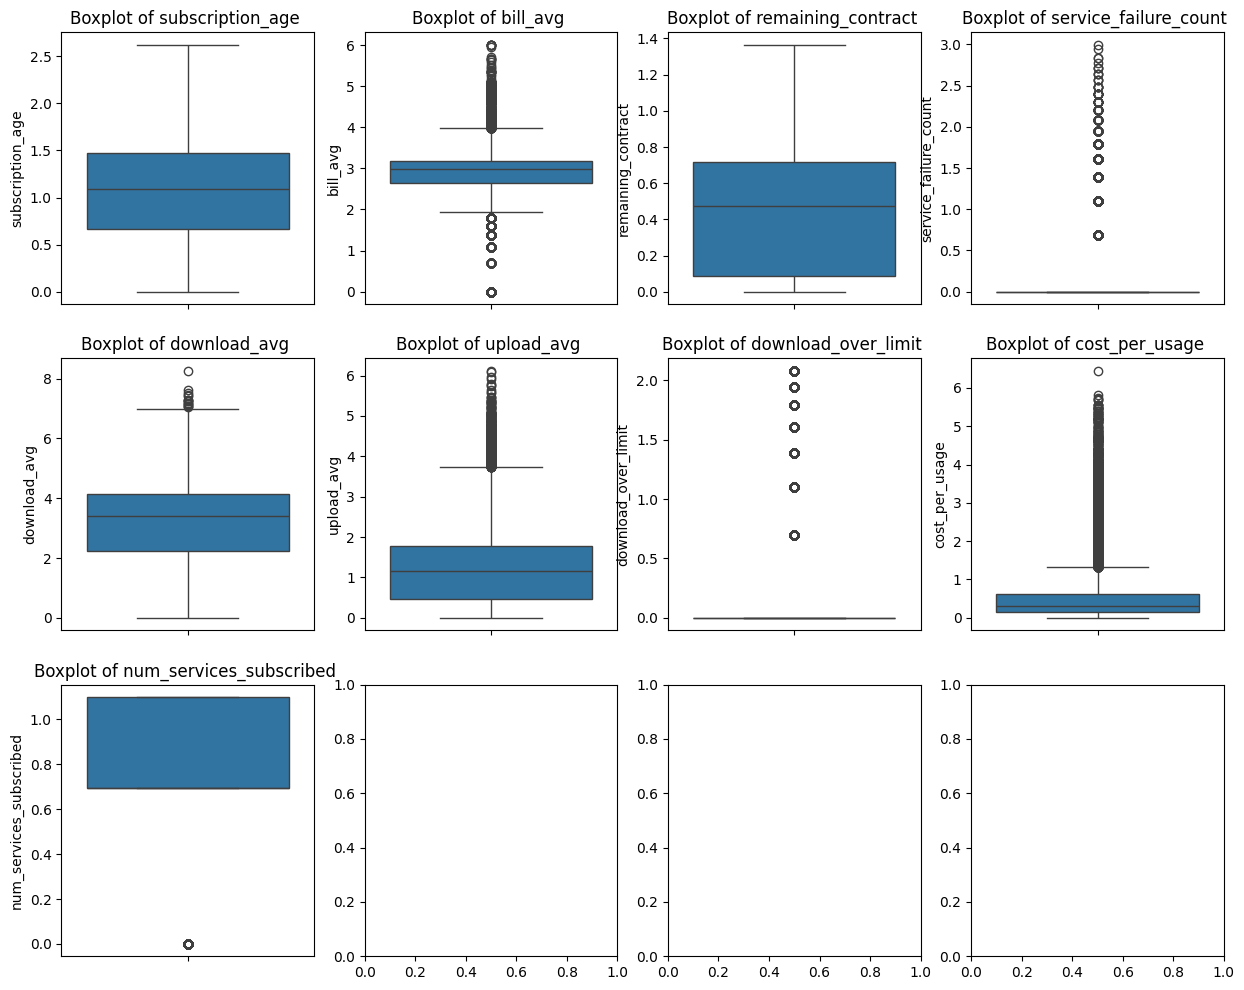

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(15, 12))

axes = axes.flatten()

for i, col in enumerate(Numeric_cols):
    sns.boxplot(y=X_train[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col} ")
    
plt.show()

## TRansforming train 



In [ ]:

X_train[Numeric_cols]= scaler.fit_transform(X_train[Numeric_cols])
X_test[Numeric_cols]= scaler.transform(X_test[Numeric_cols])

clf= LogisticRegression(penalty="l2", random_state=23, solver="liblinear").fit(X_train, Y_train)
print(clf.score(X_train,Y_train))


0.824114511845131


/Users/mohaiminulislam/Desktop/ISP Customer_churn mlops/Internet Service Provider Customer Churn/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/mohaiminulislam/Desktop/ISP Customer_churn mlops/Internet Service Provider Customer Churn/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/mohaiminulislam/Desktop/ISP Customer_churn mlops/Internet Service Provider Customer Churn/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


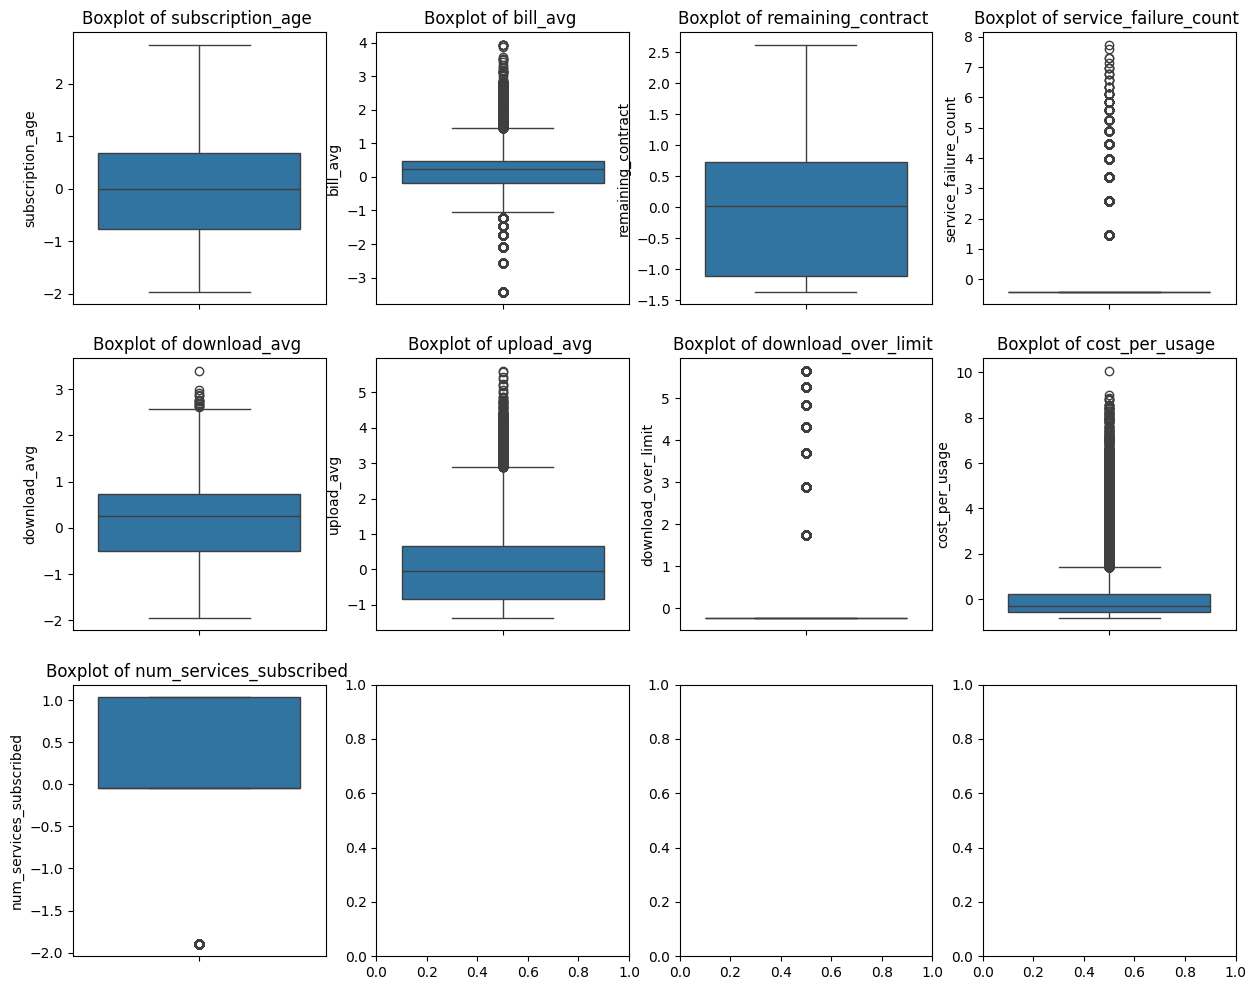

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(15, 12))

axes = axes.flatten()

for i, col in enumerate(Numeric_cols):
    sns.boxplot(y=X_train[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col} ")
    
plt.show()